- would create neural network by nn module
- built-in loss function with nn
- apply activation fun ction using nn module
- use torch.optim for updation


# NN without Hidden Layer




In [54]:
import torch
import torch.nn as nn

class Model(nn.Module):
       def __init__(self,num_features):
              super().__init__()
              self.linear = nn.Linear(num_features,1) # nn.linear(input,output)
              self.sigmoid=nn.Sigmoid()
       def forward(self,features):
              out=self.linear(features)
              out=self.sigmoid(out)
              return out


In [55]:
#create dataset

features=torch.rand(10,5)

#create model
model=Model(features.shape[1])

# call model for forward pass
model(features)  #same as model.forward -> it trigger the forward funcn inside class Model



tensor([[0.5934],
        [0.5422],
        [0.5985],
        [0.6030],
        [0.6075],
        [0.5883],
        [0.6075],
        [0.6158],
        [0.5683],
        [0.5841]], grad_fn=<SigmoidBackward0>)

In [56]:
model.linear.weight

Parameter containing:
tensor([[-0.4425, -0.1260,  0.3439,  0.0585,  0.1136]], requires_grad=True)

In [57]:
model.linear.bias



Parameter containing:
tensor([0.3817], requires_grad=True)

In [58]:
!pip install torchinfo

In [59]:
from torchinfo import summary
summary(model,input_size=(10,5))

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [10, 1]                   --
├─Linear: 1-1                            [10, 1]                   6
├─Sigmoid: 1-2                           [10, 1]                   --
Total params: 6
Trainable params: 6
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

# NN with Hidden Layer

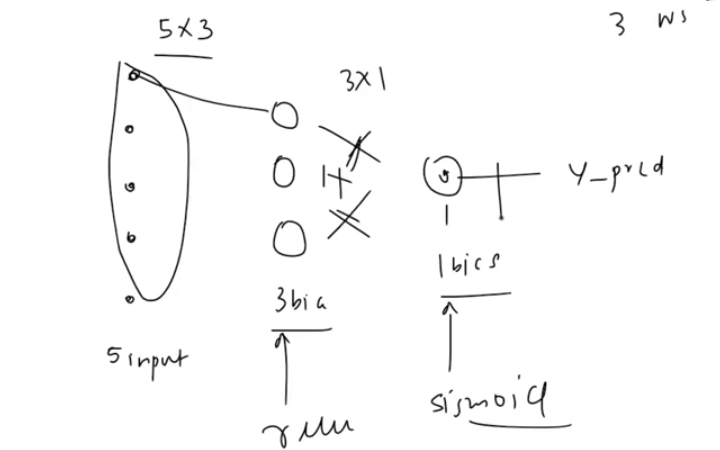

In [ ]:
import torch
import torch.nn as nn

class Model(nn.Module):
        def __init__(self,num_features):
               super().__init__()
               self.linear1 = nn.Linear(num_features,3)  #first layer(as input layer ) that gives 3 features as o/p , i/p for hidden layer
               self.relu=nn.ReLU() # hidden layer activation function
               self.linear2=nn.Linear(3,1)
               self.sigmoid=nn.Sigmoid( ) #o/p layer
        def forward(self,features):
               out=self.linear1(features)
               out=self.relu(out) 
               out=self.linear2(out)
               out=self.sigmoid(out)
               return out

In [61]:
features=torch.rand(10,5)

#create model
model=Model(features.shape[1])

In [ ]:
model(features)

tensor([[0.5948],
        [0.5916],
        [0.5948],
        [0.5643],
        [0.5838],
        [0.5843],
        [0.5948],
        [0.5948],
        [0.5948],
        [0.5898]], grad_fn=<SigmoidBackward0>)

In [63]:
model.linear1.weight

Parameter containing:
tensor([[-0.3983, -0.2230, -0.0535, -0.3285, -0.1873],
        [-0.0972, -0.0045,  0.0531, -0.3953, -0.3195],
        [ 0.0617, -0.0474, -0.0854, -0.1782, -0.3730]], requires_grad=True)

In [64]:
from torchinfo import summary
summary(model,input_size=(10,5))

Layer (type:depth-idx)                   Output Shape              Param #
Model                                    [10, 1]                   --
├─Linear: 1-1                            [10, 3]                   18
├─ReLU: 1-2                              [10, 3]                   --
├─Linear: 1-3                            [10, 1]                   4
├─Sigmoid: 1-4                           [10, 1]                   --
Total params: 22
Trainable params: 22
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00

## Sequential()


In [65]:
import torch.nn as nn
model=nn.Sequential(
    nn.Linear(20,10),
    nn.ReLU(),
    nn.Linear(10,20),
    nn.ReLU(),
    nn.Linear(20,1),
    nn.Sigmoid()
)
print(model)


Sequential(
  (0): Linear(in_features=20, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=20, bias=True)
  (3): ReLU()
  (4): Linear(in_features=20, out_features=1, bias=True)
  (5): Sigmoid()
)


### Naming the Layers

In [66]:
import torch.nn as nn
from collections import OrderedDict
model=nn.Sequential(OrderedDict([
    ("input layer", nn.Linear(10,20) ),
    ("ReLU1",nn.ReLU()),
    ("hidden layer",nn.Linear(20,10)),
    ("Relu2",nn.ReLU()),
    ("Output",nn.Linear(10,1)),
    ("Sigmoid",nn.Sigmoid())
]))

print(model)

Sequential(
  (input layer): Linear(in_features=10, out_features=20, bias=True)
  (ReLU1): ReLU()
  (hidden layer): Linear(in_features=20, out_features=10, bias=True)
  (Relu2): ReLU()
  (Output): Linear(in_features=10, out_features=1, bias=True)
  (Sigmoid): Sigmoid()
)


### Backward Pass

In [67]:
x=torch.randn(1,10)
y=model(x)
y #output after forward pass

tensor([[0.5076]], grad_fn=<SigmoidBackward0>)

### Loss Calculation

In [72]:
import torch
import torch.nn as nn

loss_fn=nn.BCELoss()
target=torch.tensor([[1.0]])
loss=loss_fn(y,target)
loss_val=loss.item()
print(loss_val)

0.6779768466949463


##One Complete training loop


In [ ]:
import torch
import torch.nn as nn
from collections import OrderedDict

model=nn.Sequential(OrderedDict([
    ("Input Layer ",nn.Linear(10,20)) , ("ReLU1", nn.ReLU()),
    ("Hidden Layer",nn.Linear(20,10)) , ("ReLU2",nn.ReLU()),
    ("Output",nn.Linear(10,1)) , ("Sigmoid",nn.Sigmoid())

]))
loss_fn=nn.BCELoss()
optimizer=torch.optim.Adam(model.parameters(), lr=1e-3)

Sequential(
  (Input Layer ): Linear(in_features=10, out_features=20, bias=True)
  (ReLU1): ReLU()
  (Hidden Layer): Linear(in_features=20, out_features=10, bias=True)
  (ReLU2): ReLU()
  (Output): Linear(in_features=10, out_features=1, bias=True)
  (Sigmoid): Sigmoid()
)
tensor([[0.5773]], grad_fn=<SigmoidBackward0>)
